In [7]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import openmc

In [8]:
# 1. Parsing robusto del file di output
data = []
path_2 = "../output_parametri/result.txt"

with open(path_2, "r") as f:
    for line in f:
        parts = line.strip().split()
        # Isolamento delle righe contenenti le 4 grandezze fisiche
        if len(parts) == 4:
            try:
                t_w = float(parts[0])
                t_f = float(parts[1])
                k = float(parts[2])
                err = float(parts[3])
                
                data.append([int(t_w), int(t_f), k,err])
            except ValueError:
                continue

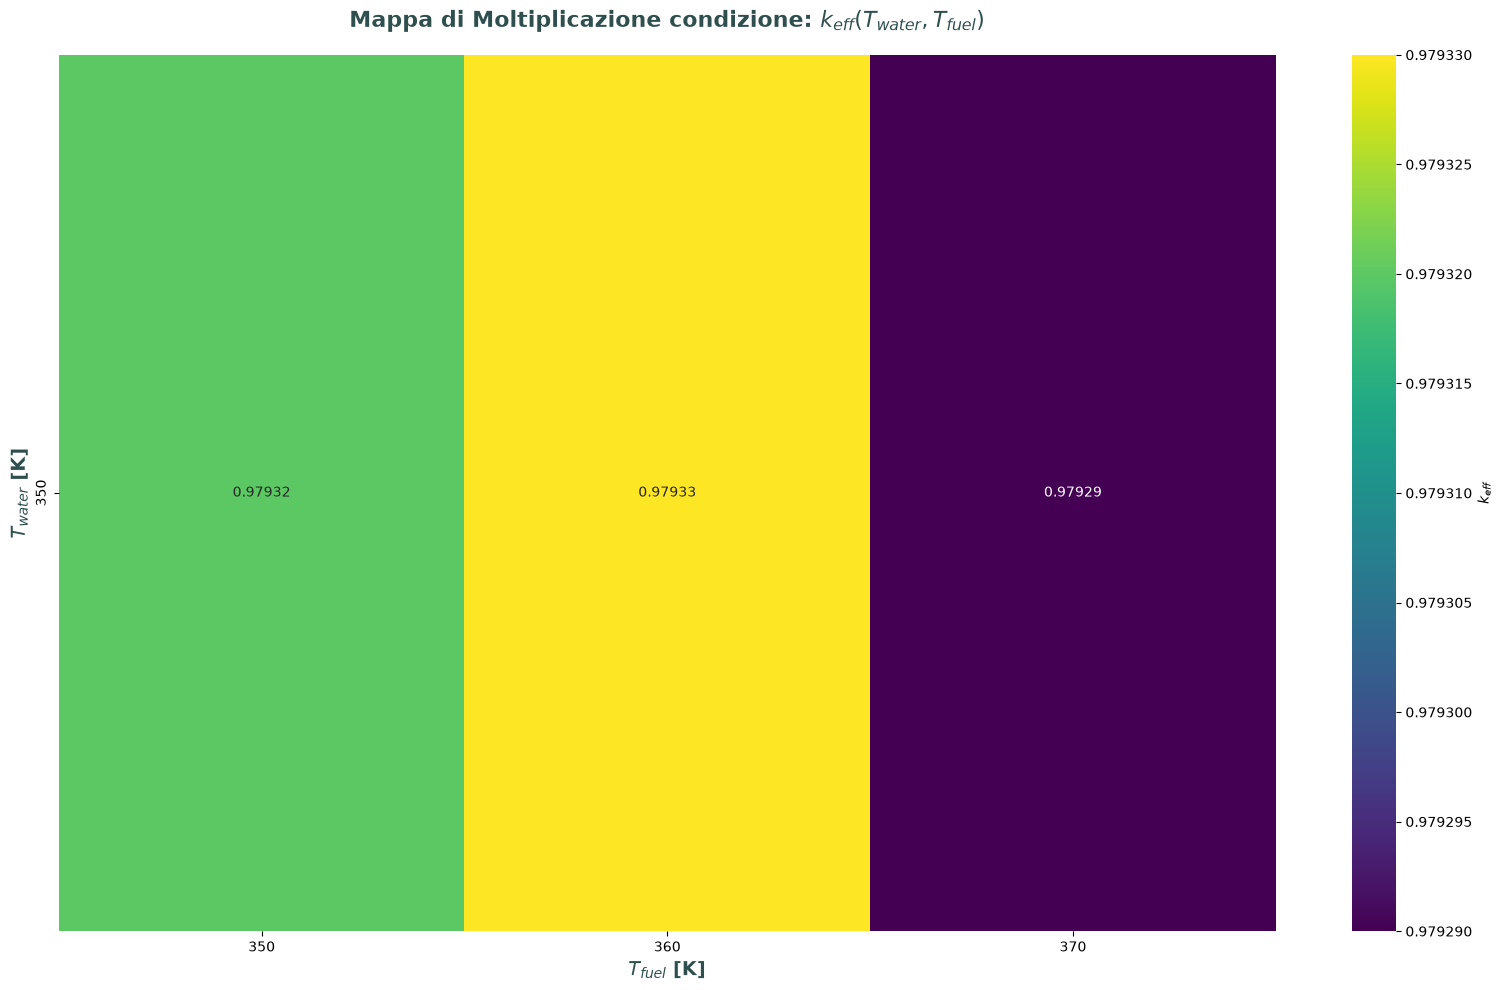

In [9]:
df = pd.DataFrame(data, columns=['T_water', 'T_fuel', 'k_eff', 'std_dev'])

# 2. Vettorizzazione 2D per la heatmap
heatmap_data = df.pivot(index='T_water', columns='T_fuel', values='k_eff')

# 3. Setup del plot (Standard Layout)
fig, ax = plt.subplots(figsize=(16, 10))

# Mappatura termica
sns.heatmap(heatmap_data, annot=True, fmt=".5f", cmap="viridis", ax=ax,
            cbar_kws={'label': '$k_{eff}$'})

# Formattazione Titolo e Labels
ax.set_title("Mappa di Moltiplicazione condizione: $k_{eff}(T_{water}, T_{fuel})$", fontsize=16, fontweight='bold', color='#2F4F4F', pad=20)
ax.set_xlabel("$T_{fuel}$ [K]", fontsize=14, fontweight='bold', color='#2F4F4F')
ax.set_ylabel("$T_{water}$ [K]", fontsize=14, fontweight='bold', color='#2F4F4F')

plt.tight_layout()
plt.show()

- Assumo che il reattore spento stia a 300 K sia in fuel che in acqua Cold Zero Power (CZP)

- definisco poi l'Hot Zero Power, cioè T_fuel = T_water ma a valori maggiori, magari 550K, cioè reattore pronto all'uso ma con ancora nessuna potenza prodotta

- infine serve il HFP = hot full power, cioè massima potenza


Per vedere una variazione:
$$\Delta\rho = \rho_2 - \rho_1 = \frac{k_2 - 1}{k_2} - \frac{k_1 - 1}{k_1} = \frac{k_2 - k_1}{k_1 \cdot k_2}$$


1. Temperature Defect (CZP $\rightarrow$ HZP) Nello stato CZP ($300\text{ K}$), il sistema è freddo. 
L'acqua ha la massima densità, offrendo la massima moderazione (spettro neutronico fortemente termico).
Scaldando il sistema allo stato HZP ($550\text{ K}$), la potenza è ancora nulla, quindi l'equilibrio termico impone $T_{fuel} = T_{water}$. 
    1) Il calo di reattività associato (Temperature Defect) è causato da due contributi: Moderator Temperature Coefficient (MTC) [Dominante]: All'aumentare della temperatura, la densità dell'acqua crolla. Questo causa due effetti: 
    - Diminuisce il potere rallentante ($\xi \Sigma_s$), indurendo lo spettro neutronico. Più neutroni vengono assorbiti nelle risonanze epitemiche dell'$^{238}\text{U}$ prima di termalizzare.
    - Aumenta il cammino libero medio neutronico, incrementando le fughe (leakage) verso i bordi del nocciolo.
    
    2) Effetto Doppler Isotermo [Minoritario]: Anche il combustibile si scalda da $300\text{ K}$ a $550\text{ K}$, causando un primo allargamento delle risonanze di assorbimento (Doppler broadening). 

2. Power Defect (HZP $\rightarrow$ HFP) Allo stato HZP, il reattore è critico e alle condizioni nominali di pressione/temperatura del fluido, ma genera $0\text{ W}$.Portando il reattore allo stato HFP (100% potenza nominale), la temperatura del moderatore resta approssimativamente costante ($T_{water} \approx 550\text{ K}$ media), ma per trasferire l'enorme calore generato per fissione nel pellet verso il fluido, si instaura un ripido gradiente termico. La temperatura media del combustibile $T_{fuel}$ schizza a valori elevati (es. $900\text{ K}$).Il calo di reattività associato (Power Defect) è dominato esclusivamente da un fenomeno: Fuel Temperature Coefficient (FTC) o Effetto Doppler Puro: L'aumento drammatico dell'agitazione termica dei nuclei di $^{238}\text{U}$ nel reticolo cristallino dell'$UO_2$ causa un allargamento (broadening) delle sezioni d'urto di cattura risonante. Sebbene l'integrale dell'area sotto la risonanza resti teoricamente costante, l'allargamento abbassa i picchi e allarga le code (riducendo il self-shielding spaziale ed energetico). Di conseguenza, aumenta drasticamente la probabilità che un neutrone venga catturato parassiticamente dall'$^{238}\text{U}$ durante il rallentamento.Il Power Defect rappresenta il feedback negativo vitale per la stabilità e la sicurezza intrinseca del reattore: all'aumentare della potenza, la fisica stessa del nocciolo "spegne" la reazione a catena. Questo valore definisce quanta reattività (es. estraendo le barre di controllo) l'operatore deve inserire per poter effettivamente far salire il reattore da $0$ al $100\%$ di potenza.


- Temperature Defect (Moderatore + Doppler base): Transizione da CZP a HZP.
$$\Delta\rho_{temp}=\frac{k_{HZP}-k_{CZP}}{k_{HZP}\cdot k_{CZP}}\cdot 10^5\quad [pcm]$$

- Power Defect (Effetto Doppler puro): Transizione da HZP a HFP.
$$\Delta\rho_{power}=\frac{k_{HFP}-k_{HZP}}{k_{HFP}\cdot k_{HZP}}\cdot 10^5\quad [pcm]$$


FATTO NEI CODICI SOPRA, UNIFICATO

Dati letti con successo: 66 righe trovate.


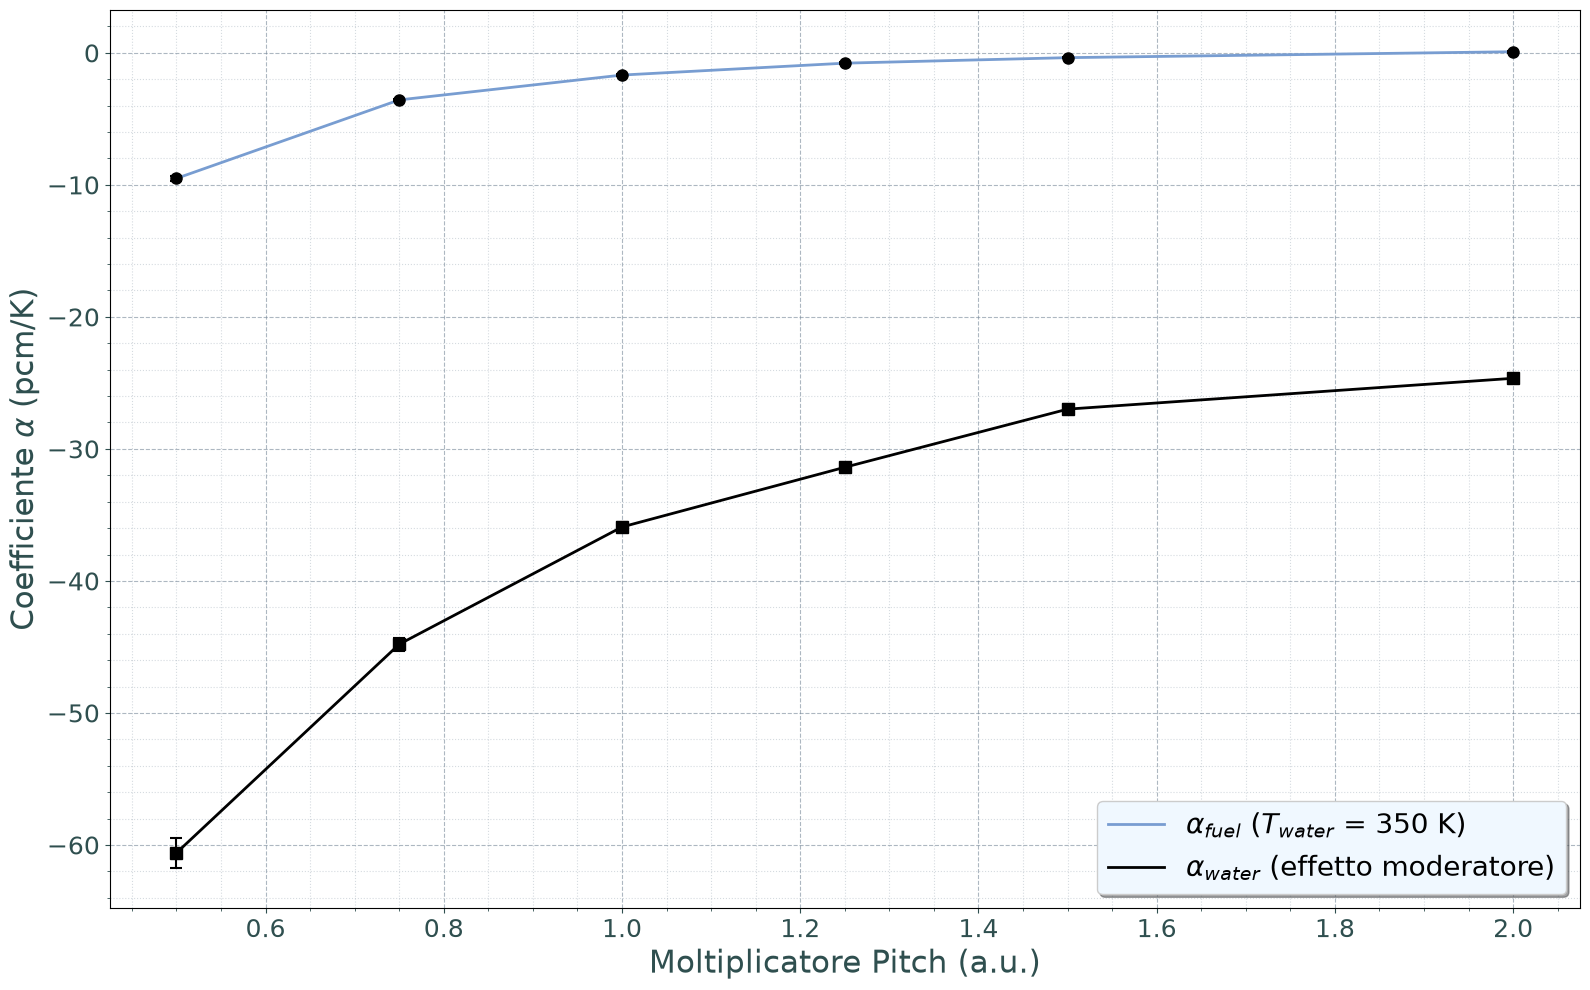

In [12]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# 1. Parsing del file di output con diagnostica
path_2 = "../result.txt"

if not os.path.exists(path_2):
    print(f"ERRORE: Il file '{path_2}' non esiste. Verifica il percorso del file!")
else:
    data = []
    with open(path_2, "r") as f:
        for line in f:
            parts = line.strip().split()
            # Selezione delle righe contenenti i 5 valori numerici
            if len(parts) == 5:
                try:
                    mult = float(parts[0])
                    t_w = float(parts[1])
                    t_f = float(parts[2])
                    k = float(parts[3])
                    err = float(parts[4])
                    data.append([mult, t_w, t_f, k, err])
                except ValueError:
                    continue

    df = pd.DataFrame(data, columns=['Pitch_Mult', 'T_water', 'T_fuel', 'k_eff', 'std_dev'])

    if df.empty:
        print("ERRORE: Il DataFrame è vuoto. Nessun dato estratto da result.txt!")
    else:
        print(f"Dati letti con successo: {len(df)} righe trovate.")

        # 2. Calcolo della reattività (pcm) e relativo errore
        df['rho_pcm'] = (df['k_eff'] - 1) / df['k_eff'] * 1e5
        df['rho_err'] = (df['std_dev'] / (df['k_eff']**2)) * 1e5

        # Modello lineare: rho(T) = alpha * T + q
        def linear_fit(T, alpha, q):
            return alpha * T + q

        multipliers = sorted(df['Pitch_Mult'].unique())
        alpha_f_vals, alpha_f_errs = [], []
        alpha_w_vals, alpha_w_errs = [], []

        for mult in multipliers:
            # Selezione per singolo Pitch
            df_mult = df[np.isclose(df['Pitch_Mult'], mult)]
            
            # CASO A: T_water fissa a 350 K -> Variazione T_fuel (Alpha Fuel)
            df_fuel = df_mult[np.isclose(df_mult['T_water'], 350)].sort_values('T_fuel')
            
            if len(df_fuel) >= 2:
                popt_f, pcov_f = curve_fit(
                    linear_fit, df_fuel['T_fuel'], df_fuel['rho_pcm'], 
                    sigma=df_fuel['rho_err'], absolute_sigma=True
                )
                a_f = popt_f[0]
                a_f_err = np.sqrt(pcov_f[0, 0])
            else:
                a_f, a_f_err = np.nan, np.nan
                
            alpha_f_vals.append(a_f)
            alpha_f_errs.append(a_f_err)
            
            # CASO B: Serie Isotermica (T_water == T_fuel) per isolare l'effetto Moderatore
            df_water = df_mult[np.isclose(df_mult['T_water'], df_mult['T_fuel'])].sort_values('T_water')
            
            if len(df_water) >= 2:
                popt_iso, pcov_iso = curve_fit(
                    linear_fit, df_water['T_water'], df_water['rho_pcm'], 
                    sigma=df_water['rho_err'], absolute_sigma=True
                )
                a_iso = popt_iso[0]
                a_iso_err = np.sqrt(pcov_iso[0, 0])
                
                # alpha_water = alpha_isothermal - alpha_fuel
                if not np.isnan(a_f):
                    a_w = a_iso - a_f
                    a_w_err = np.sqrt(a_iso_err**2 + a_f_err**2)
                else:
                    a_w, a_w_err = a_iso, a_iso_err
            else:
                a_w, a_w_err = np.nan, np.nan
                
            alpha_w_vals.append(a_w)
            alpha_w_errs.append(a_w_err)

        # 3. Setup del plot (Configurazione Estetica Uniforme)
        fig, ax = plt.subplots(figsize=(16, 10))

        # Plot Alpha Fuel (Linea Azzurra #789DD1, marcatori neri #000000)
        ax.plot(multipliers, alpha_f_vals, color='#789DD1', linestyle='-', linewidth=2, 
                label=r"$\alpha_{fuel}$ ($T_{water}$ = 350 K)")
        ax.errorbar(multipliers, alpha_f_vals, yerr=alpha_f_errs, fmt='o', 
                    color='#000000', ecolor='#000000', capsize=4, capthick=1.5, 
                    markersize=8, linestyle='none')

        # Plot Alpha Water (Linea Nera #000000, marcatori neri quadrati #000000)
        ax.plot(multipliers, alpha_w_vals, color='#000000', linestyle='-', linewidth=2, 
                label=r"$\alpha_{water}$ (effetto moderatore)")
        ax.errorbar(multipliers, alpha_w_vals, yerr=alpha_w_errs, fmt='s', 
                    color='#000000', ecolor='#000000', capsize=4, capthick=1.5, 
                    markersize=8, linestyle='none')

        # Formattazione Assi (Font size 22, colore #2F4F4F, normale, unita tra parentesi tonde)
        ax.set_xlabel("Moltiplicatore Pitch (a.u.)", fontsize=22, color='#2F4F4F', fontweight='normal')
        ax.set_ylabel(r"Coefficiente $\alpha$ (pcm/K)", fontsize=22, color='#2F4F4F', fontweight='normal')

        # Tick e Griglie
        ax.minorticks_on()
        ax.tick_params(axis='both', which='major', labelsize=18, colors='#2F4F4F')
        ax.tick_params(axis='both', which='minor', labelsize=12, colors='#2F4F4F')

        ax.grid(which='major', color='#778899', linestyle='--', alpha=0.6)
        ax.grid(which='minor', color='#778899', linestyle=':', alpha=0.3)

        # Legenda (Position 'best', size 20, shadow, facecolor #F0F8FF)
        ax.legend(loc='best', fontsize=20, frameon=True, shadow=True, facecolor='#F0F8FF')

        plt.tight_layout()
        plt.show()

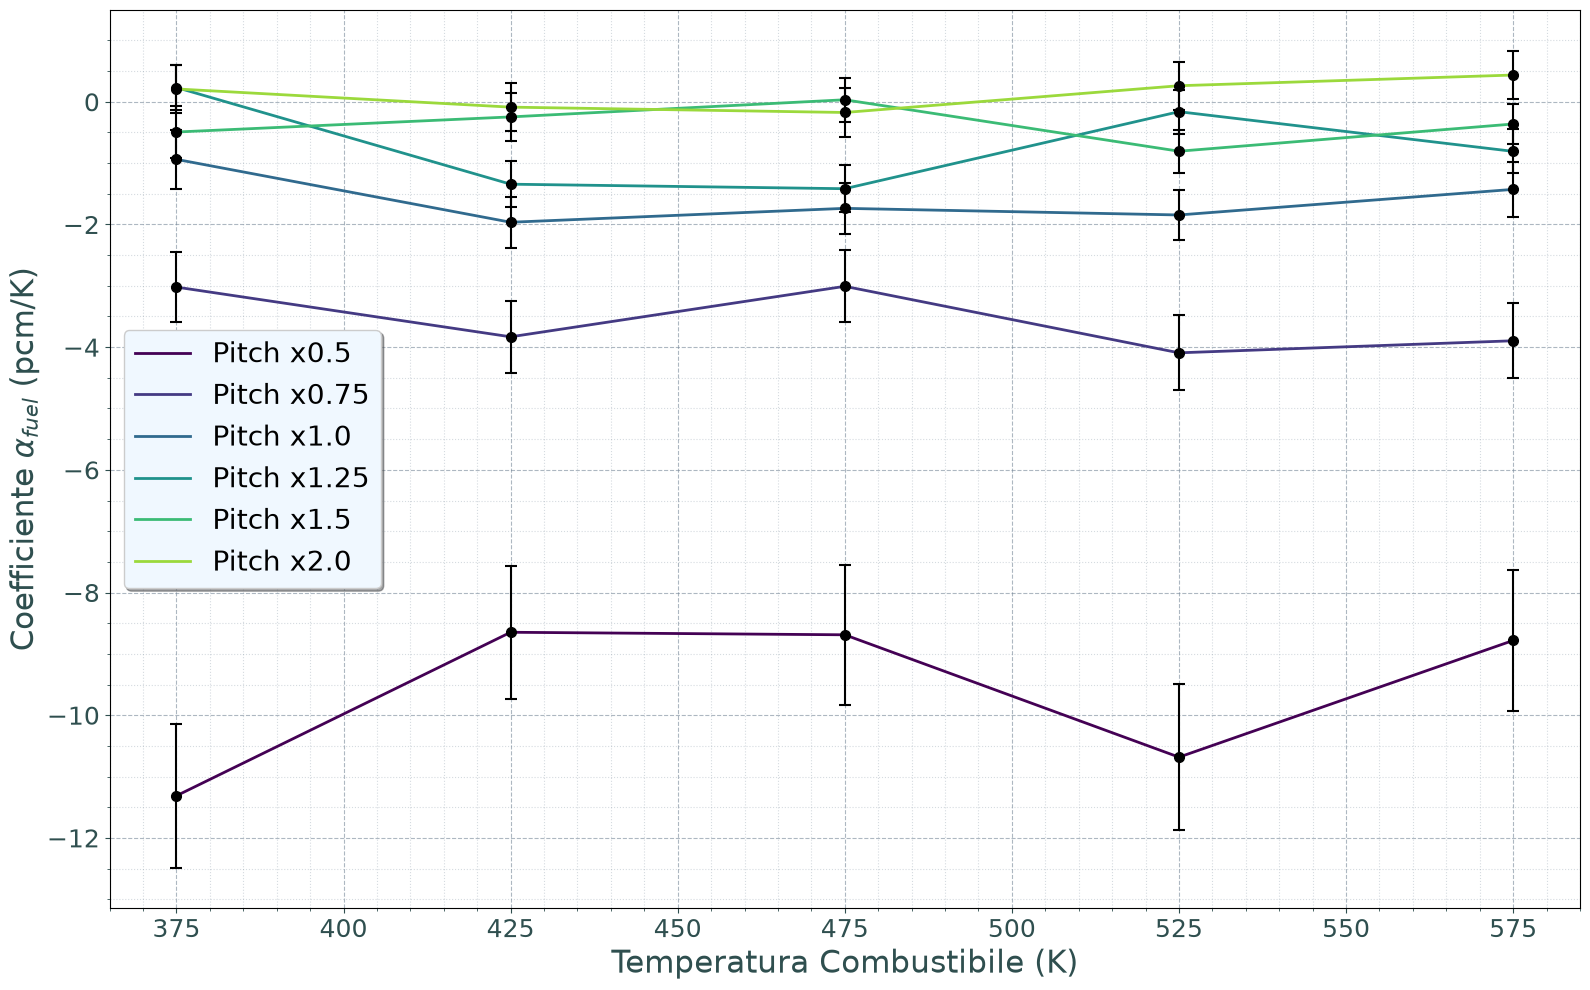

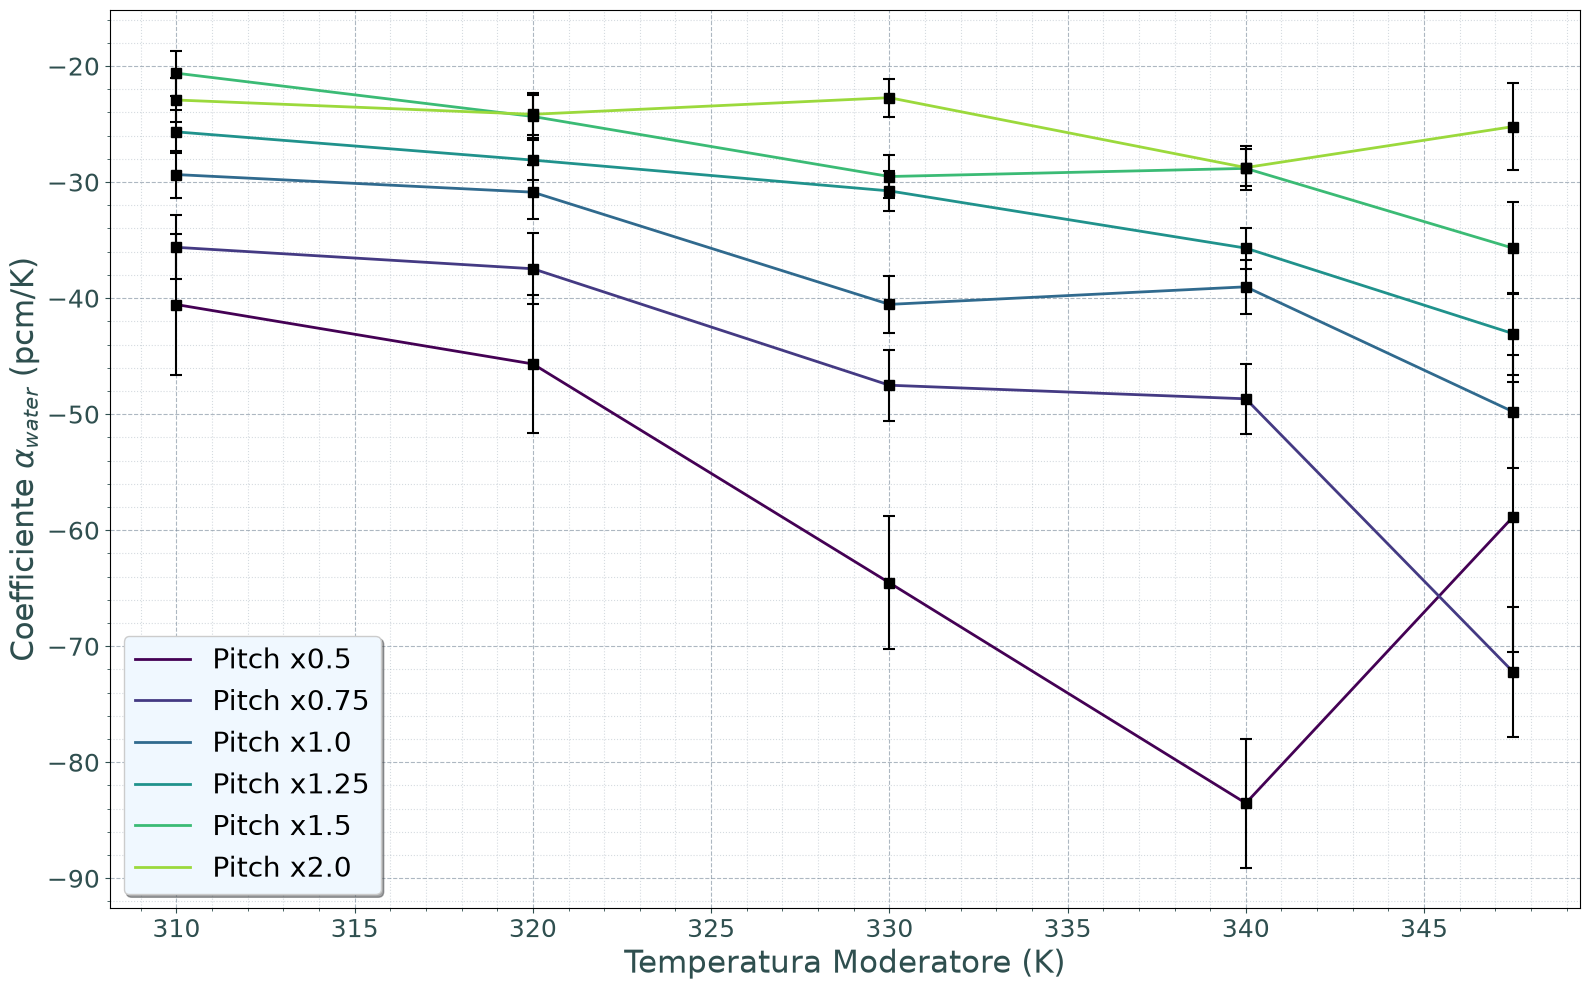

In [17]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Parsing del file di output
path_2 = "../result.txt"

data = []
with open(path_2, "r") as f:
    for line in f:
        parts = line.strip().split()
        if len(parts) == 5:
            try:
                mult = float(parts[0])
                t_w = float(parts[1])
                t_f = float(parts[2])
                k = float(parts[3])
                err = float(parts[4])
                data.append([mult, t_w, t_f, k, err])
            except ValueError:
                continue

df = pd.DataFrame(data, columns=['Pitch_Mult', 'T_water', 'T_fuel', 'k_eff', 'std_dev'])

# 2. Calcolo della reattività (pcm) e relativo errore
df['rho_pcm'] = (df['k_eff'] - 1) / df['k_eff'] * 1e5
df['rho_err'] = (df['std_dev'] / (df['k_eff']**2)) * 1e5

multipliers = sorted(df['Pitch_Mult'].unique())

# Mappa di colori distinta per identificare i vari Pitch
palette = plt.cm.viridis(np.linspace(0, 0.85, len(multipliers)))

# ==============================================================================
# FIGURA 1: alpha_fuel(T) vs T per ogni Pitch
# ==============================================================================
fig1, ax1 = plt.subplots(figsize=(16, 10))

for idx, mult in enumerate(multipliers):
    df_mult = df[np.isclose(df['Pitch_Mult'], mult)]
    df_fuel = df_mult[np.isclose(df_mult['T_water'], 350)].sort_values('T_fuel').reset_index(drop=True)
    
    if len(df_fuel) >= 2:
        # Calcolo differenze finite punto a punto
        dT = df_fuel['T_fuel'].diff().dropna()
        dRho = df_fuel['rho_pcm'].diff().dropna()
        T_mid = df_fuel['T_fuel'].rolling(2).mean().dropna()
        
        err_sq = df_fuel['rho_err']**2
        dRho_err = np.sqrt(err_sq + err_sq.shift(1)).dropna()
        
        alpha_f = dRho / dT
        alpha_f_err = dRho_err / np.abs(dT)
        
        ax1.plot(T_mid, alpha_f, color=palette[idx], linestyle='-', linewidth=2, 
                 label=f"Pitch x{mult}")
        ax1.errorbar(T_mid, alpha_f, yerr=alpha_f_err, fmt='o', 
                     color='#000000', ecolor='#000000', capsize=4, capthick=1.5, 
                     markersize=7, linestyle='none')

ax1.set_xlabel("Temperatura Combustibile (K)", fontsize=22, color='#2F4F4F', fontweight='normal')
ax1.set_ylabel(r"Coefficiente $\alpha_{fuel}$ (pcm/K)", fontsize=22, color='#2F4F4F', fontweight='normal')

ax1.minorticks_on()
ax1.tick_params(axis='both', which='major', labelsize=18, colors='#2F4F4F')
ax1.tick_params(axis='both', which='minor', labelsize=12, colors='#2F4F4F')

ax1.grid(which='major', color='#778899', linestyle='--', alpha=0.6)
ax1.grid(which='minor', color='#778899', linestyle=':', alpha=0.3)

ax1.legend(loc='best', fontsize=20, frameon=True, shadow=True, facecolor='#F0F8FF')

plt.tight_layout()
plt.show()


# ==============================================================================
# FIGURA 2: alpha_water(T) vs T per ogni Pitch
# ==============================================================================
fig2, ax2 = plt.subplots(figsize=(16, 10))

for idx, mult in enumerate(multipliers):
    df_mult = df[np.isclose(df['Pitch_Mult'], mult)]
    
    # Riferimento medio alpha_fuel per isolare il moderatore
    df_fuel = df_mult[np.isclose(df_mult['T_water'], 350)].sort_values('T_fuel').reset_index(drop=True)
    a_f_ref = 0.0
    if len(df_fuel) >= 2:
        a_f_ref = (df_fuel['rho_pcm'].iloc[-1] - df_fuel['rho_pcm'].iloc[0]) / (df_fuel['T_fuel'].iloc[-1] - df_fuel['T_fuel'].iloc[0])

    df_water = df_mult[np.isclose(df_mult['T_water'], df_mult['T_fuel'])].sort_values('T_water').reset_index(drop=True)
    
    if len(df_water) >= 2:
        dT = df_water['T_water'].diff().dropna()
        dRho = df_water['rho_pcm'].diff().dropna()
        T_mid = df_water['T_water'].rolling(2).mean().dropna()
        
        err_sq = df_water['rho_err']**2
        dRho_err = np.sqrt(err_sq + err_sq.shift(1)).dropna()
        
        alpha_iso = dRho / dT
        alpha_w = alpha_iso - a_f_ref
        alpha_w_err = dRho_err / np.abs(dT)
        
        ax2.plot(T_mid, alpha_w, color=palette[idx], linestyle='-', linewidth=2, 
                 label=f"Pitch x{mult}")
        ax2.errorbar(T_mid, alpha_w, yerr=alpha_w_err, fmt='s', 
                     color='#000000', ecolor='#000000', capsize=4, capthick=1.5, 
                     markersize=7, linestyle='none')

ax2.set_xlabel("Temperatura Moderatore (K)", fontsize=22, color='#2F4F4F', fontweight='normal')
ax2.set_ylabel(r"Coefficiente $\alpha_{water}$ (pcm/K)", fontsize=22, color='#2F4F4F', fontweight='normal')

ax2.minorticks_on()
ax2.tick_params(axis='both', which='major', labelsize=18, colors='#2F4F4F')
ax2.tick_params(axis='both', which='minor', labelsize=12, colors='#2F4F4F')

ax2.grid(which='major', color='#778899', linestyle='--', alpha=0.6)
ax2.grid(which='minor', color='#778899', linestyle=':', alpha=0.3)

ax2.legend(loc='best', fontsize=20, frameon=True, shadow=True, facecolor='#F0F8FF')

plt.tight_layout()
plt.show()